# Weekly Loss Report
**Reporting week:** Oct 19-25, 2026  |  **Source:** company app (Supabase)  |  **Scope:** Waste only (Breakage, Item Search, Repeat Trip)

In [1]:
import sys
from datetime import timedelta
sys.path.insert(0, "../src")
from reusables import *
from supabase_pull import load_waste, count_jobs
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Markdown, display
pd.set_option("display.float_format", "{:,.2f}".format)

# ---- Edit these each week -------------------------------------------------
# Reporting week
WEEK_START      = "2026-10-19"      # Monday
WEEK_LABEL      = "Week of Oct 19-25"
WEEK_JOBS       = 32                # None = count from the app

# Previous week
LAST_WEEK_START = "2026-10-12"      # Monday
LAST_WEEK_END   = "2026-10-18"      # Sunday
LAST_WEEK_LABEL = "Week of Oct 12-18"
LAST_WEEK_JOBS  = 36                # None = count from the app

RUNNING_LABEL   = "Running average"
# ---------------------------------------------------------------------------

week_start = pd.Timestamp(WEEK_START).date()
week_end   = week_start + timedelta(days=7)          # following Monday (not included)
last_start = pd.Timestamp(LAST_WEEK_START).date()
last_end   = pd.Timestamp(LAST_WEEK_END).date()

# App timestamps are UTC: pull a day either side, then filter on the local date
df = load_waste(str(last_start - timedelta(days=1)), end=str(week_end + timedelta(days=1)))
df["kind"] = df["kind"].replace({"Lost Item": "Item Search"})

this_week = df[(df["incident_date"] >= week_start) & (df["incident_date"] < week_end)]
last_week = df[(df["incident_date"] >= last_start) & (df["incident_date"] <= last_end)]

if WEEK_JOBS is None:
    WEEK_JOBS = count_jobs(str(week_start), str(week_end - timedelta(days=1)))
if LAST_WEEK_JOBS is None:
    LAST_WEEK_JOBS = count_jobs(str(last_start), str(last_end))

weeks        = {LAST_WEEK_LABEL: last_week, WEEK_LABEL: this_week}      # oldest first
jobs_by_week = {LAST_WEEK_LABEL: LAST_WEEK_JOBS, WEEK_LABEL: WEEK_JOBS}

table = compare_weeks(weeks, jobs_by_week)                              # previous week, reporting week, change
average_per_100 = running_average(weeks, jobs_by_week)["Per 100 jobs ($)"].sum()

In [2]:
print_setup()

## Summary

In [3]:
if this_week.empty:
    display(Markdown(f"- No waste events were recorded for {WEEK_LABEL}."))
else:
    tot  = table.loc["Total"]
    cost = tot[(WEEK_LABEL, "Cost ($)")]
    cur  = tot[(WEEK_LABEL, "Per 100 jobs ($)")]
    prev = tot[(LAST_WEEK_LABEL, "Per 100 jobs ($)")]

    def versus(reference, name):
        if not reference:
            return f"There is no {name} figure to compare with."
        pct = (cur / reference - 1) * 100
        if round(pct) == 0:
            return f"Cost per 100 jobs was in line with {name} (${reference:,.0f})."
        return (f"Cost per 100 jobs was **{abs(pct):.0f}% {'higher' if pct > 0 else 'lower'}** "
                f"than {name} (${reference:,.0f}).")

    by_type = table.drop("Total")[(WEEK_LABEL, "Cost ($)")]
    worst, worst_cost = by_type.idxmax(), by_type.max()

    display(Markdown("\n".join([
        f"- **{WEEK_LABEL}:** {int(tot[(WEEK_LABEL, 'Events')])} waste events costing ${cost:,.2f} "
        f"across {WEEK_JOBS} jobs (${cur:,.0f} per 100 jobs).",
        f"- {versus(prev, f'the previous week ({LAST_WEEK_LABEL})')}",
        f"- {versus(average_per_100, 'the average of the two weeks')}",
        f"- Largest cost driver: **{worst}** (${worst_cost:,.2f}, {worst_cost / cost * 100:.0f}% of the week's waste cost).",
    ])))

- **Week of Oct 19-25:** 9 waste events costing $796.95 across 32 jobs ($2,490 per 100 jobs).
- Cost per 100 jobs was **43% higher** than the previous week (Week of Oct 12-18) ($1,740).
- Cost per 100 jobs was **19% higher** than the average of the two weeks ($2,093).
- Largest cost driver: **Breakage** ($616.00, 77% of the week's waste cost).

## Waste by type: previous week vs reporting week
Costs are totals. "Per 100 jobs" adjusts for how busy each week was, and the change compares it with the previous week (red = cost went up, green = down). A dash means there was nothing to compare with.

In [4]:
style_comparison(table)

## Waste Event Details

In [5]:
cols = ["incident_date", "event_no", "kind", "job", "job_type", "title", "hours", "other_cost", "total_cost"]
cols = [c for c in cols if c in this_week.columns]       # skips any column your data doesn't have

details = (this_week[cols]
           .sort_values("total_cost", ascending=False)
           .rename(columns={"incident_date": "Date", "event_no": "Event", "kind": "Type", "job": "Job",
                            "job_type": "Job type", "title": "What happened", "hours": "Hours",
                            "other_cost": "Other ($)", "total_cost": "Total ($)"}))

style_details(details)

Date,Event,Type,Job,Job type,What happened,Hours,Other ($),Total ($)
Oct 22,W-2026-0023,Breakage,,,Furniture damaged,0.0,$495.00,$495.00
Oct 20,W-2026-0027,Item Search,6260 Lake Plantation Dr,water,Search,2.9,$0.00,$61.25
Oct 23,W-2026-0029,Breakage,1322 Ingleside Ave,water,Broken glass,0.0,$50.00,$50.00
Oct 21,W-2026-0032,Breakage,854 Summer Bay Dr,water,Broken glass,0.0,$50.00,$50.00
Oct 21,W-2026-0025,Item Search,6260 Lake Plantation Dr,water,Search,1.8,$0.00,$38.50
Oct 21,W-2026-0024,Item Search,6260 Lake Plantation Dr,water,Search,1.8,$0.00,$38.50
Oct 20,W-2026-0026,Item Search,6260 Lake Plantation Dr,water,Search,1.6,$0.00,$34.30
Oct 21,W-2026-0033,Breakage,854 Summer Bay Dr,water,Dented white shelf,0.0,$21.00,$21.00
Oct 20,W-2026-0028,Item Search,6260 Lake Plantation Dr,water,Search,0.4,$0.00,$8.40


## Charts

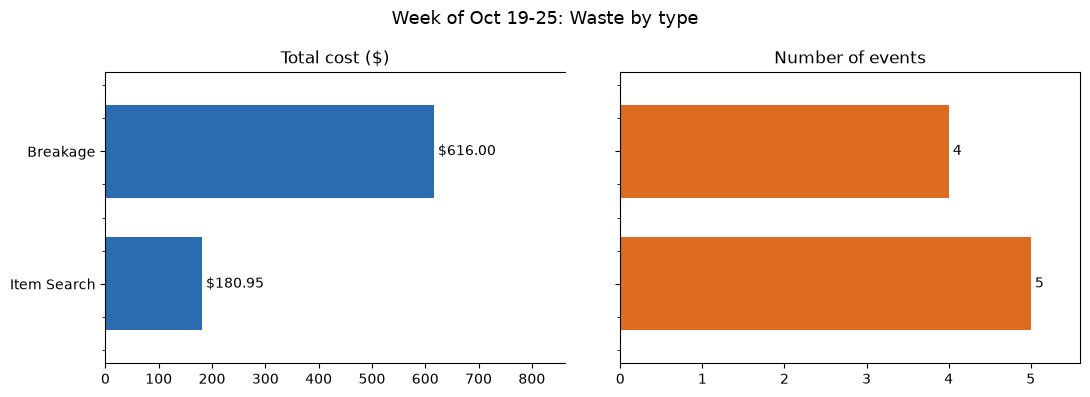

In [6]:
if this_week.empty:
    display(Markdown(f"No waste events were recorded for {WEEK_LABEL}."))
else:
    cost_events_chart(cost_by(this_week), title=f"{WEEK_LABEL}: Waste by type")

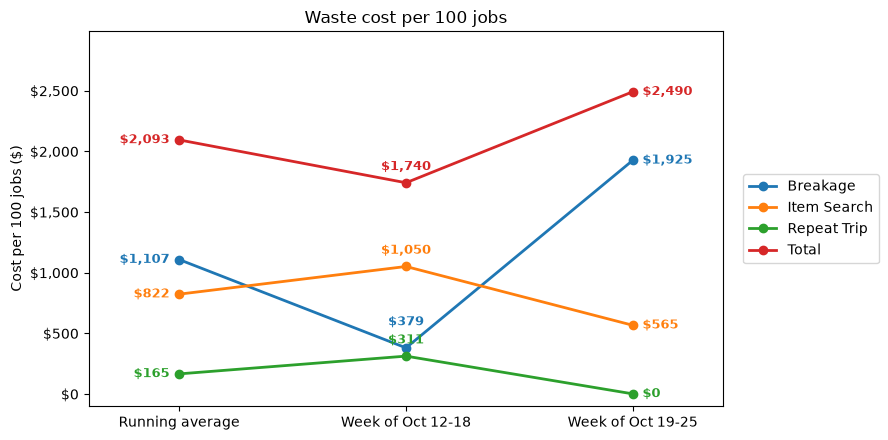

In [7]:
chart_weeks, chart_jobs = with_running_average(weeks, jobs_by_week, label=RUNNING_LABEL)
weekly_cost_chart(chart_weeks, jobs=chart_jobs, title="Waste cost per 100 jobs")

In [8]:
display(Markdown(f"""## Data notes
- Costs come from the company app as entered: labor at $21.00/hr, mileage at $0.70/mile.
- Cost per 100 jobs is each week's waste cost divided by that week's job count ({LAST_WEEK_LABEL}: {LAST_WEEK_JOBS} jobs; {WEEK_LABEL}: {WEEK_JOBS} jobs).
- The running average is the combined waste cost of the weeks shown divided by their combined jobs, so a busier week counts for more.
- Item Search covers time spent searching for misplaced or lost items.
- Only two weeks of data are available so far, so the comparison shows direction, not a trend.
"""))

## Data notes
- Costs come from the company app as entered: labor at $21.00/hr, mileage at $0.70/mile.
- Cost per 100 jobs is each week's waste cost divided by that week's job count (Week of Oct 12-18: 36 jobs; Week of Oct 19-25: 32 jobs).
- The running average is the combined waste cost of the weeks shown divided by their combined jobs, so a busier week counts for more.
- Item Search covers time spent searching for misplaced or lost items.
- Only two weeks of data are available so far, so the comparison shows direction, not a trend.
